# Atividade Somativa 2 - Técnicas de Machine Learning

## Introdução

Este trabalho é uma continuidade da Atividade Somativa 1, utilizando o mesmo dataset **NBA Players Stats**.

O objetivo continua sendo prever a variável **WinShares**, que representa uma estimativa da contribuição de um jogador para as vitórias de sua equipe ao longo de uma temporada.

Como a variável alvo é numérica e contínua, o problema é classificado como um problema de **regressão supervisionada**.

Nesta segunda parte, o foco está em reorganizar o fluxo de Machine Learning utilizando um **Pipeline**, de forma que a preparação dos dados e o treinamento do modelo sejam executados de maneira integrada e mais organizada.

## Importação das Bibliotecas

Nesta etapa foram importadas as bibliotecas necessárias para carregar os dados, dividir a base entre treino e teste, preparar as variáveis, criar o pipeline, treinar o modelo e avaliar os resultados.

In [9]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt


## Carregamento do Dataset

O dataset utilizado nesta atividade é o mesmo da Parte 1: **NBA Players Stats**. Ele contém estatísticas de jogadores da NBA desde 1950 até 2017.

A variável que será prevista é **WinShares**.

In [10]:
df = pd.read_csv('nba_stats.csv')

print(df.shape)

df.head()

(24624, 22)


,Ano,Posicao,Idade,Jogos,TrueShootingPercentage,FreeThrowRate,OffensiveWinShares,DefensiveWinShares,WinShares,FieldGoals,...,TwoPointFieldGoals,TwoPointFieldGoalAttempts,TwoPointFieldGoalPercentage,EffectiveFieldGoalPercentage,FreeThrows,FreeThrowAttempts,FreeThrowPercentage,Assists,PersonalFouls,Points
0,1950,G-F,31.0,63,0.368,0.467,-0.1,3.6,3.5,144,...,144,516,0.279,0.279,170,241,0.705,176,217,458
1,1950,SG,29.0,49,0.435,0.387,1.6,0.6,2.2,102,...,102,274,0.372,0.372,75,106,0.708,109,99,279
2,1950,SF,25.0,67,0.394,0.259,0.9,2.8,3.6,174,...,174,499,0.349,0.349,90,129,0.698,140,192,438
3,1950,F,24.0,15,0.312,0.395,-0.5,-0.1,-0.6,22,...,22,86,0.256,0.256,19,34,0.559,20,29,63
4,1950,F,24.0,13,0.308,0.378,-0.5,-0.1,-0.6,21,...,21,82,0.256,0.256,17,31,0.548,20,27,59


## Definição das Variáveis

A variável **WinShares** foi definida como variável alvo.

As colunas **OffensiveWinShares** e **DefensiveWinShares** foram removidas dos atributos preditores porque possuem relação direta com a variável alvo, o que poderia gerar vazamento de informação e deixar o resultado artificialmente alto.

In [11]:
df = df.dropna(subset=['WinShares'])

X = df.drop(columns=['WinShares', 'OffensiveWinShares', 'DefensiveWinShares'])
y = df['WinShares']

print(X.shape)
print(y.shape)

(24585, 19)
(24585,)


## Divisão entre Treino e Teste

Conforme solicitado na orientação da atividade, a divisão entre treino e teste foi realizada antes da preparação dos dados.

Foram utilizados 75% dos dados para treinamento e 25% para teste.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (18438, 19)
Teste: (6147, 19)


## Criação do Pipeline

Nesta etapa foi criado um pipeline para reunir as etapas de preparação dos dados, seleção de atributos e treinamento do modelo.

O pipeline realiza o tratamento de valores ausentes, transforma variáveis categóricas com One-Hot Encoding, seleciona os atributos mais relevantes com SelectKBest e treina o modelo Random Forest Regressor.

In [13]:
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X_train.select_dtypes(include=['object', 'string']).columns

preprocessamento = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_cols)
    ]
)

pipeline = Pipeline(steps=[
    ('preprocessamento', preprocessamento),
    ('selecao_atributos', SelectKBest(score_func=f_regression, k=10)),
    ('modelo', RandomForestRegressor(n_estimators=100, random_state=42))
])

## Treinamento do Modelo

O modelo utilizado foi o **Random Forest Regressor**, o mesmo algoritmo utilizado na Parte 1.

O treinamento foi realizado utilizando apenas a base de treino.

In [14]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('selecao_atributos', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Ano','Posicao','Idade',...,'Assists','PersonalFouls','Points']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This sub

## Atributos Selecionados

A tabela abaixo apresenta os atributos selecionados pela técnica SelectKBest dentro do pipeline. Essa etapa ajuda a identificar quais variáveis apresentaram maior relação estatística com a variável alvo WinShares.

In [19]:
nomes_atributos = pipeline.named_steps['preprocessamento'].get_feature_names_out()
mascara = pipeline.named_steps['selecao_atributos'].get_support()

atributos_selecionados = pd.DataFrame({
    'Atributo Selecionado': nomes_atributos[mascara]
})

atributos_selecionados

,Atributo Selecionado
0,num__Jogos
1,num__FieldGoals
2,num__FieldGoalAttempts
3,num__TwoPointFieldGoals
4,num__TwoPointFieldGoalAttempts
5,num__FreeThrows
6,num__FreeThrowAttempts
7,num__Assists
8,num__PersonalFouls
9,num__Points


## Predições na Base de Teste

Após o treinamento, o pipeline foi utilizado para realizar previsões sobre a base de teste.

In [20]:
predicoes = pipeline.predict(X_test)

predicoes[:10]

array([ 9.049e+00,  7.500e-02,  2.880e-01,  5.510e+00,  7.780e-01,
        4.674e+00,  5.541e+00, -1.000e-03,  1.005e+00,  0.000e+00])

## Visualização dos Resultados

O gráfico abaixo compara os valores reais de WinShares com os valores previstos pelo modelo. Quanto mais próximos os pontos estiverem de uma linha diagonal imaginária, melhor é a previsão.

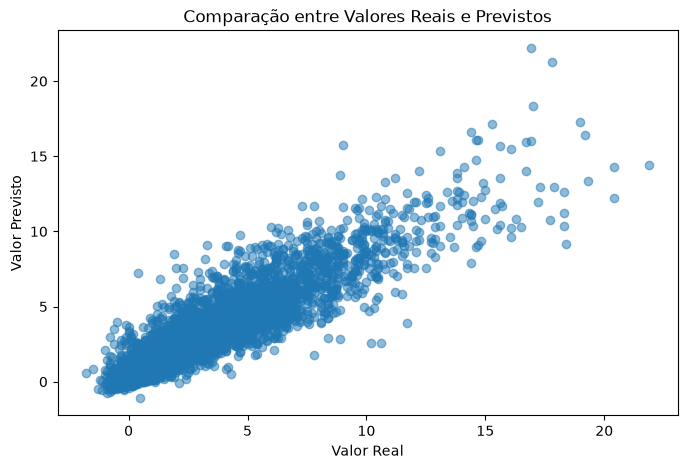

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, predicoes, alpha=0.5)
plt.xlabel('Valor Real')
plt.ylabel('Valor Previsto')
plt.title('Comparação entre Valores Reais e Previstos')
plt.show()

## Avaliação do Modelo

Para avaliar o desempenho do modelo foram utilizadas métricas de regressão.

As métricas escolhidas foram:

- **MAE**: erro absoluto médio;
- **RMSE**: raiz do erro quadrático médio;
- **R²**: coeficiente de determinação.

In [22]:
mae = mean_absolute_error(y_test, predicoes)
rmse = mean_squared_error(y_test, predicoes) ** 0.5
r2 = r2_score(y_test, predicoes)

metricas = pd.DataFrame({
    'Métrica': ['MAE', 'RMSE', 'R²'],
    'Valor': [mae, rmse, r2]
})

metricas

,Métrica,Valor
0,MAE,0.729353
1,RMSE,1.185712
2,R²,0.850510


## Comparação entre Valores Reais e Previstos

A tabela abaixo apresenta uma comparação entre os valores reais de WinShares e os valores previstos pelo pipeline para os primeiros registros da base de teste.

In [23]:
resultado = pd.DataFrame({
    'Valor Real': y_test.values,
    'Valor Previsto': predicoes
})

resultado.head(20)

,Valor Real,Valor Previsto
0,11.8,9.0490
1,0.3,0.0750
2,0.7,0.2880
3,4.5,5.5100
4,1.1,0.7780
5,4.7,4.6740
6,5.9,5.5410
7,-0.1,-0.0010
8,0.5,1.0050
9,0.0,0.0000


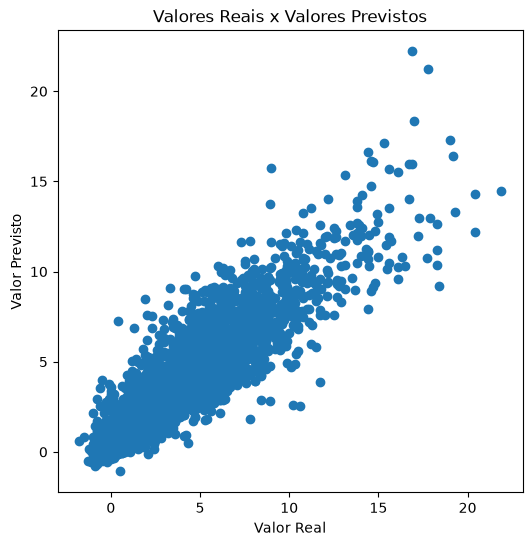

In [24]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, predicoes)
plt.xlabel("Valor Real")
plt.ylabel("Valor Previsto")
plt.title("Valores Reais x Valores Previstos")
plt.show()

## Conclusão

Nesta segunda parte da atividade foi desenvolvido um pipeline de Machine Learning para prever a variável **WinShares** utilizando o dataset NBA Players Stats.

A principal diferença em relação à Parte 1 foi a reorganização do fluxo do projeto. Primeiro foi realizada a divisão entre treino e teste e, somente depois, a preparação dos dados foi aplicada dentro do pipeline. Isso torna o processo mais adequado, pois evita que informações da base de teste influenciem as etapas de preparação e seleção de atributos.

Além disso, as colunas **OffensiveWinShares** e **DefensiveWinShares** foram removidas dos atributos preditores, pois possuem relação direta com a variável alvo. Essa decisão torna a avaliação do modelo mais realista.

O modelo utilizado foi o **Random Forest Regressor**, mantendo o mesmo algoritmo da primeira parte. Na base de teste, o modelo obteve **MAE de aproximadamente 0,73**, **RMSE de aproximadamente 1,19** e **R² de aproximadamente 0,85**.

Esses resultados podem ser considerados bons, pois o modelo conseguiu explicar cerca de 85% da variação da variável WinShares. Ao mesmo tempo, os erros indicam que ainda existem diferenças entre os valores reais e previstos, principalmente em jogadores com desempenhos muito altos ou muito baixos.

Para melhorar o modelo, poderiam ser testadas outras configurações do Random Forest, diferentes quantidades de atributos no SelectKBest, validação cruzada e comparação com outros algoritmos de regressão.

De forma geral, o uso do pipeline deixou o processo mais organizado, reprodutível e adequado para aplicações de Machine Learning.